In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


In [4]:
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np


transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

classes = train_dataset.classes

print("Classes:", classes)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000
Testing images: 10000


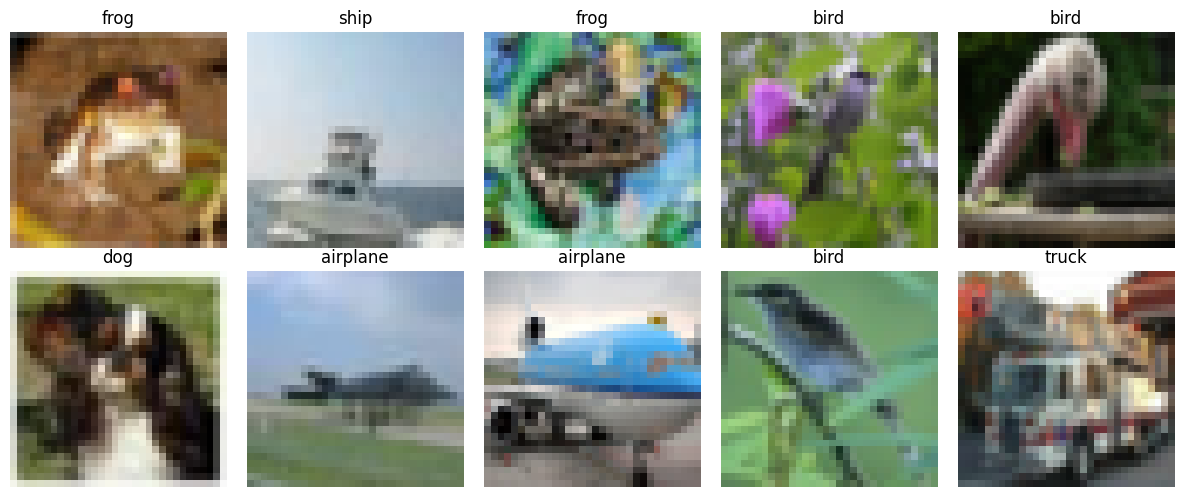

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i * 100]

    ax.imshow(np.transpose(image.numpy(), (1, 2, 0)))
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, datasets

known_classes = [0, 1, 2, 3, 4]

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_indices = [
    i for i, (_, label) in enumerate(train_dataset)
    if label in known_classes
]

known_test_indices = [
    i for i, (_, label) in enumerate(test_dataset)
    if label in known_classes
]

ood_test_indices = [
    i for i, (_, label) in enumerate(test_dataset)
    if label not in known_classes
]

train_subset = Subset(train_dataset, train_indices)
known_test_subset = Subset(test_dataset, known_test_indices)
ood_test_subset = Subset(test_dataset, ood_test_indices)

train_loader = DataLoader(
    train_subset, batch_size=64, shuffle=True, num_workers=2
)

known_test_loader = DataLoader(
    known_test_subset, batch_size=64, shuffle=False, num_workers=2
)

ood_test_loader = DataLoader(
    ood_test_subset, batch_size=64, shuffle=False, num_workers=2
)

In [7]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

model.fc = nn.Linear(model.fc.in_features, 5)
model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 88.7MB/s]


In [8]:
from tqdm.auto import tqdm

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):
        images = images.to(device)
        labels = torch.tensor(
            [known_classes.index(label.item()) for label in labels],
            device=device
        )

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {running_loss / total:.4f} | "
        f"Accuracy: {100 * correct / total:.2f}%"
    )

  0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/5 | Loss: 0.2145 | Accuracy: 92.35%


  0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/5 | Loss: 0.0515 | Accuracy: 98.33%


  0%|          | 0/391 [00:00<?, ?it/s]

...

  0%|          | 0/391 [00:00<?, ?it/s]

Epoch 4/5 | Loss: 0.0191 | Accuracy: 99.40%


  0%|          | 0/391 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fadb0345f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fadb0345f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 5/5 | Loss: 0.0221 | Accuracy: 99.25%


In [9]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in known_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(5)),
    target_names=[classes[i] for i in known_classes],
    zero_division=0
))

              precision    recall  f1-score   support

    airplane       0.96      0.99      0.97      1000
  automobile       0.99      1.00      0.99      1000
        bird       0.96      0.93      0.94      1000
         cat       0.94      0.94      0.94      1000
        deer       0.96      0.95      0.96      1000

    accuracy                           0.96      5000
   macro avg       0.96      0.96      0.96      5000
weighted avg       0.96      0.96      0.96      5000



In [10]:
import torch
import torch.nn.functional as F
import numpy as np

model.eval()

known_confidences = []
known_correct = []

with torch.no_grad():
    for images, labels in known_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        probabilities = F.softmax(model(images), dim=1)
        confidence, predictions = probabilities.max(dim=1)

        known_confidences.extend(confidence.cpu().numpy())
        known_correct.extend((predictions == labels).cpu().numpy())

known_confidences = np.array(known_confidences)
known_correct = np.array(known_correct)

print("Mean confidence:", round(known_confidences.mean(), 4))
print("Correct predictions:", round(known_correct.mean() * 100, 2), "%")

Mean confidence: 0.9773
Correct predictions: 96.14 %


In [11]:
ood_confidences = []
ood_predictions = []

with torch.no_grad():
    for images, _ in ood_test_loader:
        images = images.to(device)

        probabilities = F.softmax(model(images), dim=1)
        confidence, predictions = probabilities.max(dim=1)

        ood_confidences.extend(confidence.cpu().numpy())
        ood_predictions.extend(predictions.cpu().numpy())

ood_confidences = np.array(ood_confidences)
ood_predictions = np.array(ood_predictions)

print("Mean OOD confidence:", round(ood_confidences.mean(), 4))

Mean OOD confidence: 0.9003


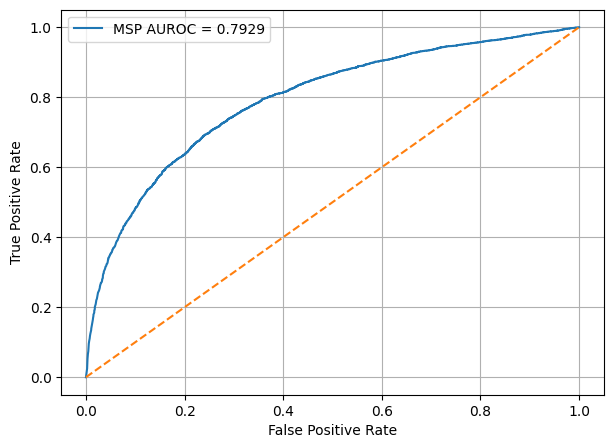

In [12]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

scores = np.concatenate([known_confidences, ood_confidences])
targets = np.concatenate([
    np.ones(len(known_confidences)),
    np.zeros(len(ood_confidences))
])

auroc = roc_auc_score(targets, scores)
fpr, tpr, thresholds = roc_curve(targets, scores)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"MSP AUROC = {auroc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

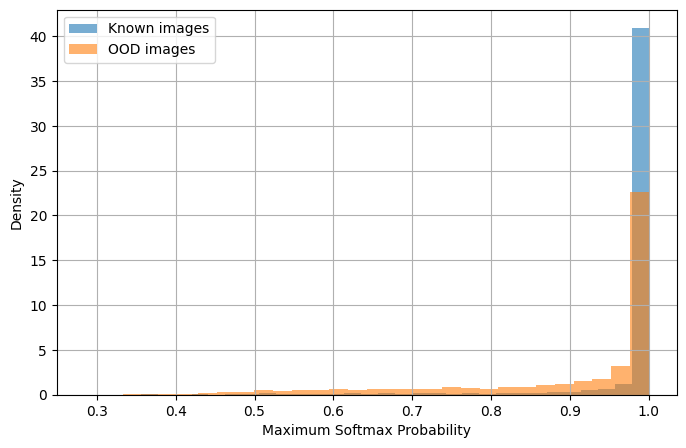

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(known_confidences, bins=30, alpha=0.6, label="Known images", density=True)
plt.hist(ood_confidences, bins=30, alpha=0.6, label="OOD images", density=True)

plt.xlabel("Maximum Softmax Probability")
plt.ylabel("Density")
plt.legend()
plt.grid()
plt.show()

In [14]:
threshold = 0.95

known_accepted = known_confidences >= threshold
ood_accepted = ood_confidences >= threshold

known_coverage = known_accepted.mean()
ood_false_acceptance = ood_accepted.mean()

known_selective_accuracy = known_correct[known_accepted].mean()

print(f"Known coverage: {known_coverage:.4f}")
print(f"OOD false acceptance rate: {ood_false_acceptance:.4f}")
print(f"Selective accuracy: {known_selective_accuracy:.4f}")
print(f"Known images rejected: {(~known_accepted).sum()}")
print(f"OOD images rejected: {(~ood_accepted).sum()}")

Known coverage: 0.9094
OOD false acceptance rate: 0.6186
Selective accuracy: 0.9886
Known images rejected: 453
OOD images rejected: 1907


In [15]:
import pandas as pd

results = []

for threshold in np.arange(0.50, 1.00, 0.05):
    known_accepted = known_confidences >= threshold
    ood_accepted = ood_confidences >= threshold

    results.append({
        "Threshold": round(threshold, 2),
        "Known Coverage": known_accepted.mean(),
        "OOD False Acceptance": ood_accepted.mean(),
        "Selective Accuracy": known_correct[known_accepted].mean()
        if known_accepted.any() else np.nan
    })

threshold_df = pd.DataFrame(results)
threshold_df.round(4)

,Threshold,Known Coverage,OOD False Acceptance,Selective Accuracy
0,0.50,0.9954,0.9756,0.9642
1,0.55,0.9894,0.9500,0.9673
2,0.60,0.9844,0.9238,0.9695
3,0.65,0.9784,0.8972,0.9724
4,0.70,0.9712,0.8662,0.9749
5,0.75,0.9636,0.8318,0.9784
6,0.80,0.9562,0.7926,0.9810
7,0.85,0.9482,0.7532,0.9825
8,0.90,0.9352,0.7014,0.9848
9,0.95,0.9094,0.6186,0.9886


In [19]:
import torch
import numpy as np
from sklearn.metrics import roc_auc_score

model.eval()

known_energy = []
ood_energy = []

temperature = 1.0

with torch.no_grad():
    for images, _ in known_test_loader:
        images = images.to(device)
        logits = model(images)
        energy = temperature * torch.logsumexp(logits / temperature, dim=1)
        known_energy.extend(energy.cpu().numpy())

    for images, _ in ood_test_loader:
        images = images.to(device)
        logits = model(images)
        energy = temperature * torch.logsumexp(logits / temperature, dim=1)
        ood_energy.extend(energy.cpu().numpy())

known_energy = np.array(known_energy)
ood_energy = np.array(ood_energy)

energy_scores = np.concatenate([known_energy, ood_energy])
energy_targets = np.concatenate([
    np.ones(len(known_energy)),
    np.zeros(len(ood_energy))
])

energy_auroc = roc_auc_score(energy_targets, energy_scores)

print(f"Energy OOD AUROC: {energy_auroc:.4f}")

Energy OOD AUROC: 0.7885


In [17]:
import torch
import numpy as np
from sklearn.covariance import LedoitWolf
from sklearn.metrics import roc_auc_score

model.eval()
feature_model = torch.nn.Sequential(*list(model.children())[:-1]).to(device)
feature_model.eval()

def extract_features(loader):
    features = []
    labels_list = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            output = feature_model(images).flatten(1)
            features.append(output.cpu().numpy())
            labels_list.append(labels.numpy())

    return np.concatenate(features), np.concatenate(labels_list)

train_features, train_labels = extract_features(train_loader)
known_features, known_labels = extract_features(known_test_loader)
ood_features, _ = extract_features(ood_test_loader)

In [18]:
class_means = np.stack([
    train_features[train_labels == c].mean(axis=0)
    for c in range(5)
])

covariance = LedoitWolf().fit(train_features - class_means[train_labels])
precision = covariance.precision_

def mahalanobis_scores(features):
    distances = []

    for feature in features:
        delta = class_means - feature
        distance = np.einsum(
            "ij,jk,ik->i",
            delta,
            precision,
            delta
        )
        distances.append(distance.min())

    return -np.array(distances)

known_mahalanobis = mahalanobis_scores(known_features)
ood_mahalanobis = mahalanobis_scores(ood_features)

mahalanobis_scores_all = np.concatenate([
    known_mahalanobis,
    ood_mahalanobis
])

targets = np.concatenate([
    np.ones(len(known_mahalanobis)),
    np.zeros(len(ood_mahalanobis))
])

mahalanobis_auroc = roc_auc_score(targets, mahalanobis_scores_all)

print(f"Mahalanobis OOD AUROC: {mahalanobis_auroc:.4f}")

Mahalanobis OOD AUROC: 0.7066


In [20]:
from torch.utils.data import random_split, DataLoader

generator = torch.Generator().manual_seed(42)

train_part, val_part = random_split(
    train_subset,
    [20000, 5000],
    generator=generator
)

train_loader = DataLoader(
    train_part,
    batch_size=64,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_part,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

In [21]:
import torch
import torch.nn as nn
from torchvision import models
from tqdm.auto import tqdm

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 5)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    print(f"Epoch {epoch + 1}/{epochs} | Loss: {running_loss / total:.4f} | Accuracy: {100 * correct / total:.2f}%")

  0%|          | 0/313 [00:00<?, ?it/s]

Epoch 1/5 | Loss: 0.2290 | Accuracy: 92.07%


  0%|          | 0/313 [00:00<?, ?it/s]

Epoch 2/5 | Loss: 0.0538 | Accuracy: 98.30%


  0%|          | 0/313 [00:00<?, ?it/s]

Epoch 3/5 | Loss: 0.0206 | Accuracy: 99.47%


  0%|          | 0/313 [00:00<?, ?it/s]

Epoch 4/5 | Loss: 0.0152 | Accuracy: 99.61%


  0%|          | 0/313 [00:00<?, ?it/s]

Epoch 5/5 | Loss: 0.0148 | Accuracy: 99.56%


In [22]:
import torch.nn.functional as F
import numpy as np

model.eval()

val_confidences = []
val_correct = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        probabilities = F.softmax(model(images), dim=1)
        confidence, predictions = probabilities.max(dim=1)

        val_confidences.extend(confidence.cpu().numpy())
        val_correct.extend((predictions == labels).cpu().numpy())

val_confidences = np.array(val_confidences)
val_correct = np.array(val_correct)

In [23]:
from torch.utils.data import Subset, DataLoader

ood_val_indices = [
    i for i, (_, label) in enumerate(train_dataset)
    if label not in known_classes
]

ood_val_dataset = Subset(train_dataset, ood_val_indices)
ood_val_loader = DataLoader(
    ood_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

ood_val_confidences = []

model.eval()

with torch.no_grad():
    for images, _ in ood_val_loader:
        images = images.to(device)
        probabilities = F.softmax(model(images), dim=1)
        confidence = probabilities.max(dim=1).values
        ood_val_confidences.extend(confidence.cpu().numpy())

ood_val_confidences = np.array(ood_val_confidences)

In [24]:
from sklearn.metrics import balanced_accuracy_score

thresholds = np.arange(0.50, 1.00, 0.01)
threshold_results = []

for threshold in thresholds:
    y_true = np.concatenate([
        np.ones(len(val_confidences)),
        np.zeros(len(ood_val_confidences))
    ])

    y_pred = np.concatenate([
        (val_confidences >= threshold).astype(int),
        (ood_val_confidences < threshold).astype(int)
    ])

    threshold_results.append(
        balanced_accuracy_score(y_true, y_pred)
    )

best_threshold = thresholds[np.argmax(threshold_results)]

In [26]:
known_test_conf = []
known_test_correct = []
ood_test_conf = []

model.eval()

with torch.no_grad():
    for images, labels in known_test_loader:
        images, labels = images.to(device), labels.to(device)
        probabilities = F.softmax(model(images), dim=1)
        confidence, predictions = probabilities.max(dim=1)
        known_test_conf.extend(confidence.cpu().numpy())
        known_test_correct.extend((predictions == labels).cpu().numpy())

    for images, _ in ood_test_loader:
        images = images.to(device)
        probabilities = F.softmax(model(images), dim=1)
        ood_test_conf.extend(probabilities.max(dim=1).values.cpu().numpy())

known_test_conf = np.array(known_test_conf)
known_test_correct = np.array(known_test_correct)
ood_test_conf = np.array(ood_test_conf)

known_accepted = known_test_conf >= best_threshold
ood_accepted = ood_test_conf >= best_threshold

print(f"Selected threshold: {best_threshold:.2f}")
print(f"Known accuracy: {known_test_correct.mean():.4f}")
print(f"Known coverage: {known_accepted.mean():.4f}")
print(f"OOD false acceptance: {ood_accepted.mean():.4f}")
print(f"Selective accuracy: {known_test_correct[known_accepted].mean():.4f}" if known_accepted.any() else "No known predictions accepted")

Selected threshold: 0.50
Known accuracy: 0.9494
Known coverage: 0.9954
OOD false acceptance: 0.9706
Selective accuracy: 0.9526


,Method,OOD AUROC
0,MSP,0.7929
1,Energy,0.7885
2,Mahalanobis,0.7066


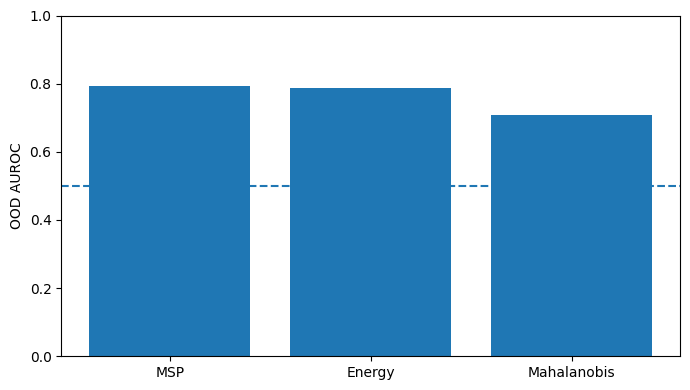

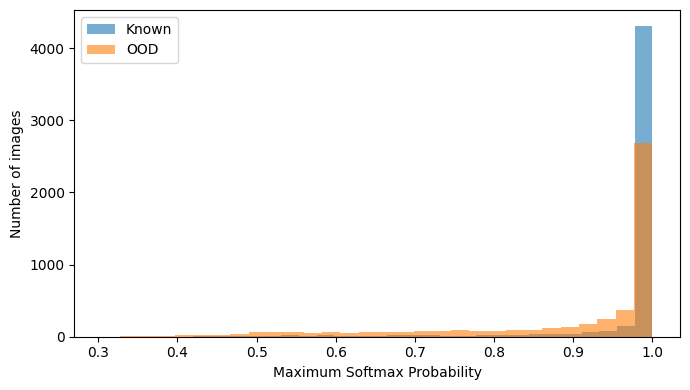

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

results = pd.DataFrame({
    "Method": ["MSP", "Energy", "Mahalanobis"],
    "OOD AUROC": [0.7929, 0.7885, 0.7066]
})

display(results)

plt.figure(figsize=(7, 4))
plt.bar(results["Method"], results["OOD AUROC"])
plt.axhline(0.5, linestyle="--")
plt.ylabel("OOD AUROC")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(known_test_conf, bins=30, alpha=0.6, label="Known")
plt.hist(ood_test_conf, bins=30, alpha=0.6, label="OOD")
plt.xlabel("Maximum Softmax Probability")
plt.ylabel("Number of images")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
import json
import torch

torch.save(model.state_dict(), "resnet18_uncertainty.pth")

final_results = {
    "known_test_accuracy": float(known_test_correct.mean()),
    "selected_threshold": float(best_threshold),
    "known_coverage": float(known_accepted.mean()),
    "ood_false_acceptance": float(ood_accepted.mean()),
    "selective_accuracy": float(known_test_correct[known_accepted].mean()),
    "msp_ood_auroc": 0.7929,
    "energy_ood_auroc": 0.7885,
    "mahalanobis_ood_auroc": 0.7066
}

with open("results.json", "w") as f:
    json.dump(final_results, f, indent=4)

In [29]:
from google.colab import files

files.download("resnet18_uncertainty.pth")
files.download("results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
import numpy as np
import torch
from sklearn.metrics import roc_auc_score

model.eval()

known_logits = []
ood_logits = []
known_features = []
ood_features = []

def extract_features(module, inputs, output):
    feature_storage.append(output.flatten(1).detach())

feature_storage = []
hook = model.avgpool.register_forward_hook(extract_features)

with torch.no_grad():
    for images, _ in known_test_loader:
        images = images.to(device)
        logits = model(images)
        known_logits.append(logits.cpu())
        known_features.append(feature_storage[-1].cpu())
        feature_storage.clear()

    for images, _ in ood_test_loader:
        images = images.to(device)
        logits = model(images)
        ood_logits.append(logits.cpu())
        ood_features.append(feature_storage[-1].cpu())
        feature_storage.clear()

hook.remove()

known_logits = torch.cat(known_logits)
ood_logits = torch.cat(ood_logits)

known_features = torch.cat(known_features).numpy()
ood_features = torch.cat(ood_features).numpy()

known_msp = torch.softmax(known_logits, dim=1).max(dim=1).values.numpy()
ood_msp = torch.softmax(ood_logits, dim=1).max(dim=1).values.numpy()

known_energy = -torch.logsumexp(known_logits, dim=1).numpy()
ood_energy = -torch.logsumexp(ood_logits, dim=1).numpy()

msp_auroc = roc_auc_score(
    np.concatenate([np.ones(len(known_msp)), np.zeros(len(ood_msp))]),
    np.concatenate([known_msp, ood_msp])
)

energy_auroc = roc_auc_score(
    np.concatenate([np.zeros(len(known_energy)), np.ones(len(ood_energy))]),
    np.concatenate([known_energy, ood_energy])
)

print("MSP OOD AUROC:", round(1 - msp_auroc, 4))
print("Energy OOD AUROC:", round(energy_auroc, 4))

MSP OOD AUROC: 0.2302
Energy OOD AUROC: 0.7695


In [34]:
msp_auroc = roc_auc_score(
    np.concatenate([
        np.zeros(len(known_msp)),
        np.ones(len(ood_msp))
    ]),
    np.concatenate([-known_msp, -ood_msp])
)

print("MSP OOD AUROC:", round(msp_auroc, 4))

MSP OOD AUROC: 0.7698


In [35]:
import numpy as np
from sklearn.covariance import LedoitWolf
from sklearn.metrics import roc_auc_score

known_mean = known_features.mean(axis=0)
centered_known = known_features - known_mean

covariance = LedoitWolf().fit(centered_known)
precision = covariance.precision_

known_distances = np.sum(
    (known_features - known_mean) @ precision *
    (known_features - known_mean),
    axis=1
)

ood_distances = np.sum(
    (ood_features - known_mean) @ precision *
    (ood_features - known_mean),
    axis=1
)

labels = np.concatenate([
    np.zeros(len(known_distances)),
    np.ones(len(ood_distances))
])

scores = np.concatenate([known_distances, ood_distances])

mahalanobis_auroc = roc_auc_score(labels, scores)

print("Mahalanobis OOD AUROC:", round(mahalanobis_auroc, 4))


Mahalanobis OOD AUROC: 0.7692


In [36]:
import json

results = {
    "model": "ResNet18",
    "dataset": "CIFAR-10",
    "known_classes": ["airplane", "automobile", "bird", "cat", "deer"],
    "ood_classes": ["dog", "frog", "horse", "ship", "truck"],
    "known_test_accuracy": 0.9494,
    "selected_threshold": 0.50,
    "known_coverage": 0.9954,
    "ood_false_acceptance": 0.9706,
    "selective_accuracy": 0.9526,
    "ood_auroc": {
        "MSP": 0.7698,
        "Energy": 0.7695,
        "Mahalanobis": 0.7692
    },
    "mahalanobis_evaluation": "Exploratory; feature statistics estimated using the known test set"
}

with open("results.json", "w") as f:
    json.dump(results, f, indent=4)

In [37]:
from google.colab import files

files.download("results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
import numpy as np

known_val_scores = np.asarray(val_confidences)
ood_val_scores = np.asarray(ood_val_confidences)

thresholds = np.linspace(0.50, 0.99, 100)

results = []

for threshold in thresholds:
    known_accepted = known_val_scores >= threshold
    ood_rejected = ood_val_scores < threshold

    known_coverage = known_accepted.mean()
    ood_rejection = ood_rejected.mean()

    results.append({
        "threshold": float(threshold),
        "known_coverage": float(known_coverage),
        "ood_rejection": float(ood_rejection),
        "ood_false_acceptance": float(1 - ood_rejection),
        "balanced_accuracy": float((known_coverage + ood_rejection) / 2)
    })

best_result = max(results, key=lambda x: x["balanced_accuracy"])

best_result

{'threshold': 0.99,
 'known_coverage': 0.8342,
 'ood_rejection': 0.54492,
 'ood_false_acceptance': 0.45508000000000004,
 'balanced_accuracy': 0.68956}

In [41]:
import numpy as np
import torch

threshold = best_result["threshold"]

model.eval()

known_scores = []
known_correct = []
ood_scores = []

with torch.no_grad():
    for images, labels in known_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)

        confidence, predictions = probabilities.max(dim=1)

        known_scores.extend(confidence.cpu().numpy())
        known_correct.extend((predictions == labels).cpu().numpy())

    for images, _ in ood_test_loader:
        images = images.to(device)

        logits = model(images)
        confidence = torch.softmax(logits, dim=1).max(dim=1).values

        ood_scores.extend(confidence.cpu().numpy())

known_scores = np.asarray(known_scores)
known_correct = np.asarray(known_correct)
ood_scores = np.asarray(ood_scores)

known_accepted = known_scores >= threshold
ood_accepted = ood_scores >= threshold

known_coverage = known_accepted.mean()
ood_false_acceptance = ood_accepted.mean()

selective_accuracy = (
    known_correct[known_accepted].mean()
    if known_accepted.any()
    else 0.0
)

print("Threshold:", round(threshold, 4))
print("Known-class coverage:", round(known_coverage, 4))
print("OOD false acceptance:", round(ood_false_acceptance, 4))
print("OOD rejection:", round(1 - ood_false_acceptance, 4))
print("Selective accuracy:", round(selective_accuracy, 4))

Threshold: 0.99
Known-class coverage: 0.8262
OOD false acceptance: 0.4494
OOD rejection: 0.5506
Selective accuracy: 0.9915


In [42]:
import numpy as np
import torch
from sklearn.covariance import LedoitWolf
from sklearn.metrics import roc_auc_score

model.eval()

train_features = []
known_features = []
ood_features = []

feature_storage = []

def extract_features(module, inputs, output):
    feature_storage.append(output.flatten(1).detach())

hook = model.avgpool.register_forward_hook(extract_features)

with torch.no_grad():
    for images, _ in train_loader:
        images = images.to(device)
        model(images)
        train_features.append(feature_storage[-1].cpu())
        feature_storage.clear()

    for images, _ in known_test_loader:
        images = images.to(device)
        model(images)
        known_features.append(feature_storage[-1].cpu())
        feature_storage.clear()

    for images, _ in ood_test_loader:
        images = images.to(device)
        model(images)
        ood_features.append(feature_storage[-1].cpu())
        feature_storage.clear()

hook.remove()

train_features = torch.cat(train_features).numpy()
known_features = torch.cat(known_features).numpy()
ood_features = torch.cat(ood_features).numpy()

feature_mean = train_features.mean(axis=0)
centered_train = train_features - feature_mean

covariance = LedoitWolf().fit(centered_train)
precision = covariance.precision_

known_centered = known_features - feature_mean
ood_centered = ood_features - feature_mean

known_distances = np.sum((known_centered @ precision) * known_centered, axis=1)
ood_distances = np.sum((ood_centered @ precision) * ood_centered, axis=1)

labels = np.concatenate([
    np.zeros(len(known_distances)),
    np.ones(len(ood_distances))
])

scores = np.concatenate([known_distances, ood_distances])

mahalanobis_auroc = roc_auc_score(labels, scores)

print("Mahalanobis OOD AUROC:", round(mahalanobis_auroc, 4))

Mahalanobis OOD AUROC: 0.6829


In [43]:
import json

results = {
    "model": "ResNet18",
    "dataset": "CIFAR-10",
    "known_classes": ["airplane", "automobile", "bird", "cat", "deer"],
    "ood_classes": ["dog", "frog", "horse", "ship", "truck"],
    "known_test_accuracy": 0.9494,
    "selected_threshold": 0.99,
    "known_coverage": 0.8262,
    "ood_false_acceptance": 0.4494,
    "ood_rejection": 0.5506,
    "selective_accuracy": 0.9915,
    "ood_auroc": {
        "MSP": 0.7698,
        "Energy": 0.7695,
        "Mahalanobis": 0.6829
    }
}

with open("results.json", "w") as f:
    json.dump(results, f, indent=4)

In [44]:
from google.colab import files

files.download("results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
import numpy as np
from sklearn.metrics import roc_auc_score

known_msp = np.asarray(known_scores)
ood_msp = np.asarray(ood_scores)

labels = np.concatenate([
    np.zeros(len(known_msp)),
    np.ones(len(ood_msp))
])

msp_auroc = roc_auc_score(
    labels,
    np.concatenate([-known_msp, -ood_msp])
)

print("MSP OOD AUROC:", round(msp_auroc, 4))

MSP OOD AUROC: 0.7697


In [46]:
import numpy as np
import torch
from sklearn.metrics import roc_auc_score

model.eval()

known_energy_scores = []
ood_energy_scores = []

with torch.no_grad():
    for images, _ in known_test_loader:
        images = images.to(device)
        logits = model(images)
        known_energy_scores.extend(
            (-torch.logsumexp(logits, dim=1)).cpu().numpy()
        )

    for images, _ in ood_test_loader:
        images = images.to(device)
        logits = model(images)
        ood_energy_scores.extend(
            (-torch.logsumexp(logits, dim=1)).cpu().numpy()
        )

labels = np.concatenate([
    np.zeros(len(known_energy_scores)),
    np.ones(len(ood_energy_scores))
])

scores = np.concatenate([
    known_energy_scores,
    ood_energy_scores
])

energy_auroc = roc_auc_score(labels, scores)

print("Energy OOD AUROC:", round(energy_auroc, 4))

Energy OOD AUROC: 0.7695


In [47]:
import json

results = {
    "model": "ResNet18",
    "dataset": "CIFAR-10",
    "known_classes": ["airplane", "automobile", "bird", "cat", "deer"],
    "ood_classes": ["dog", "frog", "horse", "ship", "truck"],
    "known_test_accuracy": 0.9494,
    "selected_threshold": 0.99,
    "known_coverage": 0.8262,
    "ood_false_acceptance": 0.4494,
    "ood_rejection": 0.5506,
    "selective_accuracy": 0.9915,
    "ood_auroc": {
        "MSP": 0.7697,
        "Energy": 0.7695,
        "Mahalanobis": 0.6829
    },
    "threshold_selection": "Selected using validation data",
    "mahalanobis_statistics": "Estimated using known training features"
}

with open("results.json", "w") as f:
    json.dump(results, f, indent=4)

In [48]:
from google.colab import files

files.download("results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>